In [30]:
import calendar
import re
import os
import subprocess

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
import csv

# 1. Read TSV and collect Chiroptera accessions
chiroptera_accessions = set()
with open("Astroviridae_30062026_annotated_MAstV_species.tsv", newline="") as fh:
    reader = csv.DictReader(fh, delimiter="\t")
    for row in reader:
        if row.get("Host_order", "").strip() == "Chiroptera":
            acc = row.get("Accession", "").strip()
            if acc:
                chiroptera_accessions.add(acc)

print(f"Found {len(chiroptera_accessions)} Chiroptera accessions")

# 2. Extract matching sequences from FASTA
keep = False
written = 0
with open("Astroviridae_30062026_1B.fna") as fin, \
     open("Chiroptera_MAstV_1B.fna", "w") as fout:
    for line in fin:
        if line.startswith(">"):
            # Header format: PX870876/k141_189198/LAO/2024/Limosa-lapponica/Aves/NA
            acc = line[1:].split("/")[0].strip()
            keep = acc in chiroptera_accessions
            if keep:
                written += 1
        if keep:
            fout.write(line)

print(f"Wrote {written} sequences to Chiroptera_MAstV_1B.fna")

Found 2025 Chiroptera accessions
Wrote 1903 sequences to Chiroptera_MAstV_1B.fna


In [36]:
astro_meta = pd.read_csv("Astroviridae_30062026_annotated_MAstV_species.tsv", sep="\t")

chiroptera_meta = astro_meta[astro_meta["Host_order"] == "Chiroptera"].copy()

D:\Users\User\AppData\Local\Temp\ipykernel_11900\84882056.py:1: DtypeWarning: Columns (0: Collection date) have mixed types. Specify dtype option on import or set low_memory=False.
  astro_meta = pd.read_csv("Astroviridae_30062026_annotated_MAstV_species.tsv", sep="\t")


In [37]:
chiroptera_meta

,Accession,LOCUS,Version,GenBank title,Release date,Organism name,Virus Lineage,Species,Family,Length,...,host_clean,Host_species,Host_genus,Host_family,Host_order,Host_class,Host_phylum,Host_kingdom,Species_ICTV,virus_name
134,PX666685,PX666685,PX666685.1,Bat bastrovirus isolate BastroV/NN59/Rus/Rosto...,24-FEB-2026,Bat bastrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,711,...,Nyctalus noctula,Nyctalus noctula,Nyctalus,Vespertilionidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
228,PX482536,PX482536,PX482536.1,Bat astrovirus isolate UF-FLMNH/2021/Ma4 polyp...,09-DEC-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,3292,...,Myotis austroriparius,Myotis austroriparius,Myotis,Vespertilionidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
426,PX459866,PX459866,PX459866.1,Bat bastrovirus isolate B1908S27B_IdeaLab_SL s...,20-OCT-2025,Bat bastrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,315,...,Pteropus medius,Pteropus medius,Pteropus,Pteropodidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
427,PX459865,PX459865,PX459865.1,Bat bastrovirus isolate B1907S26A_IdeaLab_SL s...,20-OCT-2025,Bat bastrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,222,...,Pteropus medius,Pteropus medius,Pteropus,Pteropodidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
428,PX459864,PX459864,PX459864.1,Bat bastrovirus isolate B1809S07M_IdeaLab_SL s...,20-OCT-2025,Bat bastrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,540,...,Pteropus medius,Pteropus medius,Pteropus,Pteropodidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15464,JQ814860,JQ814860,JQ814860.1,Miniopterus schreibersii astrovirus 5 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 5,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
15465,JQ814859,JQ814859,JQ814859.1,Miniopterus schreibersii astrovirus 4 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 4,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
15466,JQ814858,JQ814858,JQ814858.1,Miniopterus schreibersii astrovirus 3 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 3,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
15467,JQ814857,JQ814857,JQ814857.1,Miniopterus schreibersii astrovirus 2 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 2,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN


In [46]:
from Bio import SeqIO

# accession'ы из FASTA (первый токен заголовка до '/')
fasta_ids = {rec.id.split("/")[0] for rec in SeqIO.parse('Astroviridae_30062026_1B.faa', "fasta")}

# оставить только строки, чьи Accession есть в FASTA
orf1b_bats = chiroptera_meta[
    chiroptera_meta["Accession"].astype(str).str.strip().isin(fasta_ids)
].copy()

print(f"{len(chiroptera_meta_filtered)} из {len(chiroptera_meta)} строк осталось")

1903 из 1903 строк осталось


<Axes: >

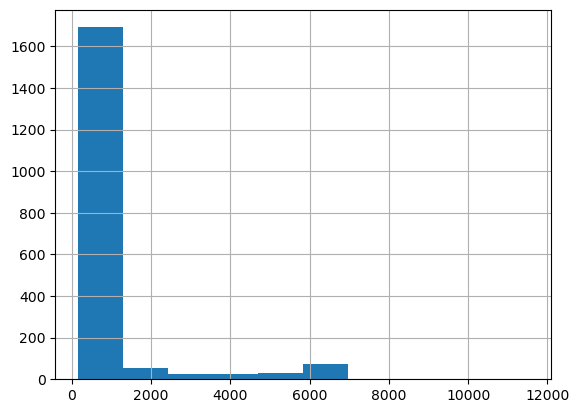

In [48]:
orf1b_bats["Length"].hist()

In [52]:
orf1b_bats= orf1b_bats[(orf1b_bats["Length"]>300) & (orf1b_bats["Length"]<2000)]

In [53]:
orf1b_bats

,Accession,LOCUS,Version,GenBank title,Release date,Organism name,Virus Lineage,Species,Family,Length,...,host_clean,Host_species,Host_genus,Host_family,Host_order,Host_class,Host_phylum,Host_kingdom,Species_ICTV,virus_name
489,OR951096,OR951096,OR951096.1,MAG: Bat astrovirus isolate JX2021 polyprotein...,18-SEP-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,1608,...,Rhinolophus affinis,Rhinolophus affinis,Rhinolophus,Rhinolophidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
490,OR951095,OR951095,OR951095.1,MAG: Bat astrovirus isolate JX2021 polyprotein...,18-SEP-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,1381,...,Rhinolophus affinis,Rhinolophus affinis,Rhinolophus,Rhinolophidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
491,OR951094,OR951094,OR951094.1,MAG: Bat astrovirus isolate FJ2021 polyprotein...,18-SEP-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,1850,...,Rhinolophus affinis,Rhinolophus affinis,Rhinolophus,Rhinolophidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
492,OR951093,OR951093,OR951093.1,MAG: Bat astrovirus isolate FJ2021 polyprotein...,18-SEP-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,960,...,Rhinolophus affinis,Rhinolophus affinis,Rhinolophus,Rhinolophidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
493,OR951092,OR951092,OR951092.1,MAG: Bat astrovirus isolate HN2021 polyprotein...,18-SEP-2025,Bat astrovirus,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,901,...,Rhinolophus affinis,Rhinolophus affinis,Rhinolophus,Rhinolophidae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15464,JQ814860,JQ814860,JQ814860.1,Miniopterus schreibersii astrovirus 5 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 5,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
15465,JQ814859,JQ814859,JQ814859.1,Miniopterus schreibersii astrovirus 4 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 4,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
15466,JQ814858,JQ814858,JQ814858.1,Miniopterus schreibersii astrovirus 3 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 3,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN
15467,JQ814857,JQ814857,JQ814857.1,Miniopterus schreibersii astrovirus 2 RNA-depe...,25-SEP-2012,Miniopterus schreibersii astrovirus 2,Viruses;Riboviria;Orthornavirae;Pisuviricota;S...,NaN,Astroviridae,387,...,Miniopterus schreibersii,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,Chordata,Metazoa,NaN,NaN


In [54]:
user_cols = ['Organism name', 'Species', 'Geo location', 'Country', 'Collection date', 'Tissue/Specimen/Source',
       'Host', 'Environmental', 'CDS count', 'host_clean',
       'Host_species', 'Host_genus', 'Host_family', 'Host_order', 'Host_class',
       'Species_ICTV']   # specify your columns
orf1b_bats[user_cols].describe(include=['object', 'category'])

D:\Users\User\AppData\Local\Temp\ipykernel_11900\314816721.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  orf1b_bats[user_cols].describe(include=['object', 'category'])


,Organism name,Species,Geo location,Country,Collection date,Tissue/Specimen/Source,Host,Environmental,host_clean,Host_species,Host_genus,Host_family,Host_order,Host_class,Species_ICTV
count,1694,185,1694,1694,1593,1205,1694,1694,1694,1489,1667,1667,1694,1694,0
unique,222,7,57,25,182,39,195,2,124,109,40,11,1,1,0
top,Mamastrovirus sp.,Bat astroviruses,Thailand,CHN,2020,rectal swab,Miniopterus magnater,No,Miniopterus magnater,Miniopterus schreibersii,Miniopterus,Miniopteridae,Chiroptera,Mammalia,NaN
freq,644,178,218,508,156,376,141,1628,141,159,424,424,1694,1694,NaN


In [6]:
import subprocess

# Search for ambiguous bases
input_path = "Chiroptera_MAstV_1B.fna"
out_dir = "."

cmd = [
    "python.exe",
    "search_amb.py",
    "-input", input_path,
    "-outdir", out_dir
]

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout)
print(result.stderr)

Number of records in fasta file: 1903
FJ571068/LS11/CHN/2007-06-06/Hipposideros-armiger/Mammalia/NA 1
FJ571066/LD77/CHN/2007-06-08/Taphozous-melanopogon/Mammalia/NA 1
PP357251/TZ32357/TZA/2018/Scotophilus-dinganii/Mammalia/NA 4
PP357250/TZ32383var1/TZA/2018/Miniopterus-fraterculus/Mammalia/NA 5
PP357249/TZ32383var2/TZA/2018/Miniopterus-fraterculus/Mammalia/NA 9
OR752541/200670/REU/2020-06-04/Mormopterus-francoismoutoui/Mammalia/NA 4
OR752540/200558/REU/2020-03-16/Mormopterus-francoismoutoui/Mammalia/NA 4
OR752539/200508/REU/2020-03-16/Mormopterus-francoismoutoui/Mammalia/NA 4
OR752538/200485/REU/2020-03-03/Mormopterus-francoismoutoui/Mammalia/NA 4
OR752537/200467/REU/2020-03-03/Mormopterus-francoismoutoui/Mammalia/NA 5
OR752536/200466/REU/2020-03-03/Mormopterus-francoismoutoui/Mammalia/NA 4
OR752535/200218/REU/2020-02-13/Mormopterus-francoismoutoui/Mammalia/NA 4
OR752534/200192/REU/2020-02-13/Mormopterus-francoismoutoui/Mammalia/NA 4
OR752533/200116/REU/2020-01-28/Mormopterus-francoism

In [18]:
from Bio import SeqIO
from Bio.SeqRecord import SeqRecord

input_path = "Chiroptera_MAstV_1B_noamb.fna"
output_path = "Chiroptera_MAstV_1B_noamb.faa"

records = (
    SeqRecord(rec.seq.translate(to_stop=True), id=rec.id, description=rec.description)
    for rec in SeqIO.parse(input_path, "fasta")
)
SeqIO.write(records, output_path, "fasta")

1683

In [ ]:
from Bio import SeqIO

faa_path = "Chiroptera_MAstV_1B_noamb.faa"

recs = [
    rec for rec in SeqIO.parse(faa_path, "fasta")
    if 100 <= len(rec.seq.replace("*", "")) <= 600
]

out_path = faa_path.replace(".faa", "_len_100.faa")
SeqIO.write(recs, out_path, "fasta")
print(f"Kept {len(recs)} sequences with 100 ≤ aa ≤ 600 -> {out_path}")

Kept 1628 sequences with 100 ≤ aa ≤ 600 -> Chiroptera_MAstV_1B_noamb_len_100.faa


In [56]:
from Bio import SeqIO

faa_path = "Chiroptera_MAstV_1B_noamb_len_100.faa"

with open("remove_weird_seqs_based_on_aln.txt") as fh:
    ids_to_remove = {line.strip() for line in fh if line.strip()}

records = list(SeqIO.parse(faa_path, "fasta"))
kept = [rec for rec in records if rec.id not in ids_to_remove]

out_path = faa_path.replace(".faa", "_filtered.faa")
SeqIO.write(kept, out_path, "fasta")
print(f"Before: {len(records)}, removed: {len(records)-len(kept)}, kept: {len(kept)} -> {out_path}")

Before: 1628, removed: 36, kept: 1592 -> Chiroptera_MAstV_1B_noamb_len_100_filtered.faa


In [57]:
import subprocess
import os

mafft_path = r"C:/MALICHAVA/Tools/mafft-win/mafft.bat"
input_faa  = "Chiroptera_MAstV_1B_noamb_len_100_filtered.faa"
output_faa = "mafft_out/Chiroptera_MAstV_1B_noamb_len_100_filtered_aln.faa"

# ensure output dir exists
os.makedirs(os.path.dirname(output_faa), exist_ok=True)

cmd = [mafft_path, "--auto", input_faa]

with open(output_faa, "w") as fout:
    result = subprocess.run(cmd, stdout=fout, stderr=subprocess.PIPE, text=True)

print(result.stderr)

Active code page: 65001
 
Preparing environment to run MAFFT on Windows. 
This may take a while, if real-time scanning by anti-virus software is on. 

It may take a while before the calculation starts
if being scanned by anti-virus software.
Also consider using a faster version for Windows 10:
https://mafft.cbrc.jp/alignment/software/wsl.html
nthread = 0
nthreadpair = 0
nthreadtb = 0
ppenalty_ex = 0
rescale = 1
Gap Penalty = -1.53, +0.00, +0.00



Making a distance matrix ..

    1 / 1592
  101 / 1592
  201 / 1592
  301 / 1592
  401 / 1592
  501 / 1592
  601 / 1592
  701 / 1592
  801 / 1592
  901 / 1592
 1001 / 1592
 1101 / 1592
 1201 / 1592
 1301 / 1592
 1401 / 1592
 1501 / 1592
done.

Constructing a UPGMA tree (efffree=0) ... 

    0 / 1592
   10 / 1592
   20 / 1592
   30 / 1592
   40 / 1592
   50 / 1592
   60 / 1592
   70 / 1592
   80 / 1592
   90 / 1592
  100 / 1592
  110 / 1592
  120 / 1592
  130 / 1592
  140 / 1592
  150 / 1592
  160 / 1592
  170 / 1592
  180 / 1592
  190 / 1592

In [60]:
from Bio import SeqIO

aln_path = "pcr_aln.faa"
min_aa = 115

records = list(SeqIO.parse(aln_path, "fasta"))
kept = [rec for rec in records if len(rec.seq.replace("-", "").replace("*", "")) >= min_aa]

out_path = aln_path.replace(".faa", f"_min{min_aa}aa.faa")
SeqIO.write(kept, out_path, "fasta")
print(f"{len(records)} -> {len(kept)} sequences, written to {out_path}")

1592 -> 1223 sequences, written to pcr_aln_min115aa.faa
